# Quickstart: one call, one verdict

Sequencing-based spatial BCR/TCR methods attach a spatial barcode to every receptor molecule. If a PCR template
switch joins the receptor to the barcode of an unrelated captured cDNA, the sequence is still right but its position
is not, and nothing on the molecule records the swap. `spaclone.run` asks, with one call, whether receptor positions
carry information beyond random placement.

This notebook runs that call on two synthetic sections with known truth:

* **real**: 30% of receptor molecules sit in their own cell; the rest were swapped to random places;
* **broken**: every molecule was swapped (genuine fraction 0).

A good test says "signal" for the first and "no signal" for the second. The notebook needs no download and runs in
under a minute.

In [1]:
import time

t_start = time.time()

import matplotlib.pyplot as plt
import pandas as pd

import spaclone

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 70)
plt.rcParams["figure.dpi"] = 100
print("spaclone", spaclone.__version__)

spaclone 1.0.0


## Two synthetic sections

`spaclone.datasets.synthetic_example` simulates a 600 µm square chip with a tissue disc (T zone, follicles, three
germinal centres, plasma-cell foci) on a 2 µm spot grid. Every B cell carries a heavy and a light chain clone, every T
cell a TRB and a TRA clone, and every receptor molecule is one of:

* `genuine`: it sits on a spot inside its own cell;
* `swapped`: its barcode was exchanged during library PCR, so it sits on the spot of a random captured cDNA, on or off
  the tissue;
* `sink`: one of many chimeric copies collected by a single barcode-sink spot.

The spot-level gene expression (GEX) holds each cell's own constant-region transcript (with detection probability
0.5), so a genuine molecule can meet its own transcript on its spot and a swapped one only by chance. The seed is fixed
(`rng=0` by default), so both sections are the same every time.

In [2]:
real = spaclone.datasets.synthetic_example(genuine_fraction=0.3)
broken = spaclone.datasets.synthetic_example(genuine_fraction=0.0)
print(real.meta["technology"], "|", real.meta["source_unit"])
print("real:  ", real.air.shape[0], "receptor molecules,", real.gex.n_obs, "GEX spots")
print("broken:", broken.air.shape[0], "receptor molecules,", broken.gex.n_obs, "GEX spots")
real.air[["spot_id", "x_um", "y_um", "locus", "clone_id", "c_call", "consensus_count", "truth"]].head()

synthetic | synthetic spot (2 µm)
real:   7954 receptor molecules, 20340 GEX spots
broken: 7954 receptor molecules, 20340 GEX spots


,spot_id,x_um,y_um,locus,clone_id,c_call,consensus_count,truth
0,126_95,252.0,190.0,TRB,TRB|TRBV5|TRBJ2|CIEKMAHISQCF,TRBC2,1.0,swapped
1,154_253,308.0,506.0,TRB,TRB|TRBV7|TRBJ4|CSIMNYQDKIWAF,TRBC2,1.0,swapped
2,90_77,180.0,154.0,IGH,IGH|IGHV5|IGHJ4|CFGKDISPGNGNVW,IGHA,3.0,swapped
3,106_237,212.0,474.0,IGH,IGH|IGHV5|IGHJ4|CFGKDISPGNGNVW,IGHA,1.0,swapped
4,66_142,132.0,284.0,IGH,IGH|IGHV5|IGHJ4|CFGKDISPGNGNVW,IGHA,3.0,swapped


Every reader in spaclone returns the same three things (a `SpatialAIR`): the receptor table `air` (one row per
molecule, contig or cell call, coordinates in µm), the spot-level GEX `gex` (an AnnData) and reader metadata `meta`.
The synthetic table also carries the truth of every molecule:

In [3]:
pd.crosstab(real.air.locus, real.air.truth, margins=True)

truth,genuine,sink,swapped,All
locus,,,,
IGH,1032,283,2348,3663
IGK,899,249,2110,3258
IGL,132,28,298,458
TRA,82,21,182,285
TRB,77,19,194,290
All,2222,600,5132,7954


Drawn at their positions, the two sections look alike. Below, genuine molecules are blue and swapped or sink
molecules grey: on the real section (left) the genuine ones gather in germinal centres and plasma-cell foci, under a
much larger cloud of swapped molecules; the broken section (right) has no genuine molecule at all. Without the truth
column, a map alone cannot tell you which kind of data you have.

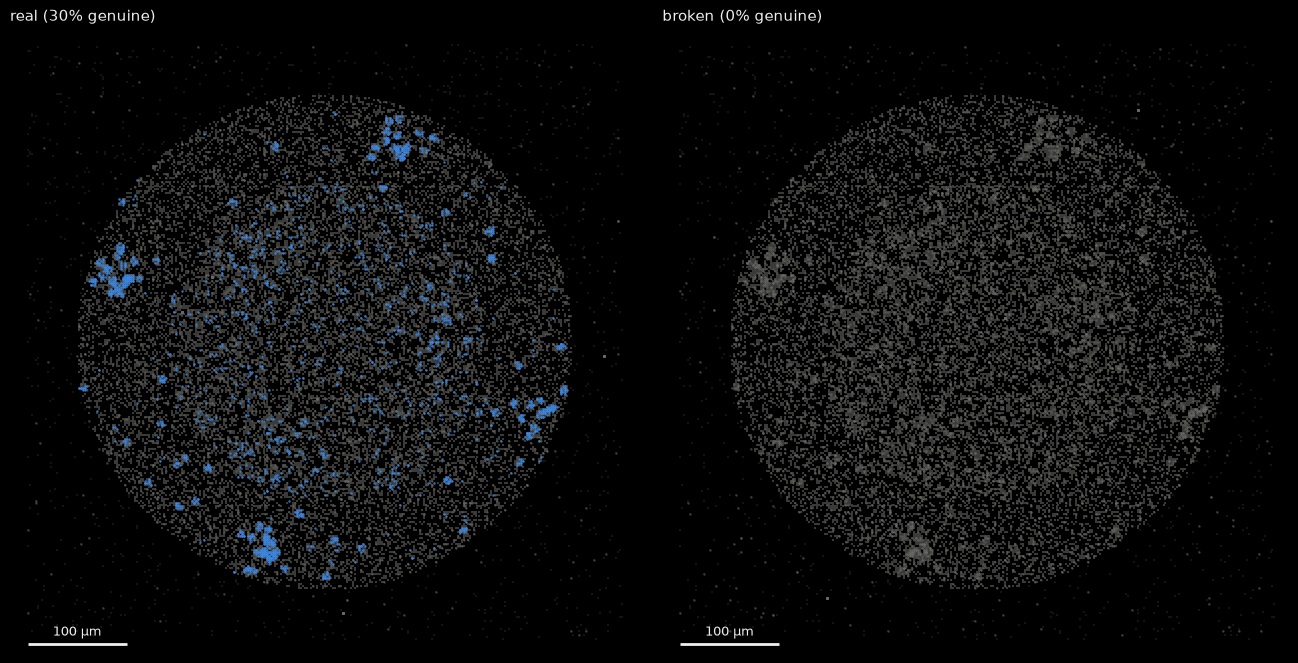

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.5), layout="constrained")
for ax, sa, title in ((axes[0], real, "real (30% genuine)"), (axes[1], broken, "broken (0% genuine)")):
    spaclone.pl.spatial_records(sa, color="truth", highlight=["genuine"], ax=ax, title=title, size=3)
plt.show()

## One call

`spaclone.run` takes the reader output (or a receptor table plus a GEX AnnData) and does, in order:

1. receptor QC metrics (`pp.qc_metrics`) and filtering (`pp.filter_records`: valid IMGT junction, productive);
2. barcode-sink detection (`pp.barcode_sinks`);
3. local Ig RNA strata from the GEX (`gex.ig_rna`), so that later tests compare like with like;
4. every location-trust test the data allow: same spot as its own transcript (`qc.same_spot`), share on its own cell
   type against random placement (`qc.own_type_share`), same-clone co-localisation within Ig RNA strata
   (`qc.colocalisation`), heavy/light pairing against a chimera-aware null (`qc.pairing`), and partner-chain sharing
   across read floors (`qc.read_floor`).

The criteria that turn test results into verdicts are fixed before the data are seen (`spaclone.qc.CRITERIA`). They
give one verdict per level: `report.verdict_molecule` (does a molecule sit on its own transcript or cell type?) and
`report.verdict_clone` (does clone identity follow position?). `report.verdict` combines the two
(`spaclone.qc.OVERALL_RULES`); only the clone level licenses clone maps.

In [5]:
report = spaclone.run(real)
report_broken = spaclone.run(broken)
print("real:  ", report.verdict)
print("broken:", report_broken.verdict)

real:   Clone positions supported: clone identity follows position; clone maps and spatial clone statistics are licensed. Molecule level: signal — molecules sit on their own transcript / cell type more often than random placement (same_spot (IGH, IGK, IGL, TRA, TRB); own_type_share (BCR, TCR)).
broken: No evidence of positional signal at the power of these data: no row reached BH q < 0.05 (absence of evidence, not evidence of absence). Power: 12 testable row(s) in 5 tests (same_spot 5, own_type_share 2, colocalisation 2, pairing 1, partner_sharing 2); molecule-level BH family m = 7, clone-level BH family m = 5. Monte-Carlo tests used B >= 200 permutations (smallest p 0.005; alpha/m >= 0.0071). A single positive row would have needed observed/chance >= 1.79 (same_spot), 1.21 (own_type_share), 1.29 (colocalisation), 1.37 (pairing), 1.84 (partner_sharing) (median over rows). Same-spot 95% upper bounds of located fraction x detection probability: IGH 3.34%, IGK 2.01%, IGL 0.42%, TRA 3.10%,

## The test table

`report.tests()` has one row per test, library and chain. `observed` is the statistic on the data, `chance` its value
under the test's null (an analytic expectation or the mean of the placebo draws), `ratio` their quotient, `q_value`
the Benjamini–Hochberg value within the rows of one level (molecule or clone), and `verdict` the pre-stated criterion
applied to them.

In [6]:
cols = ["test", "locus", "n", "observed", "chance", "ratio", "p_value", "q_value", "verdict", "note"]
report.tests()[cols]

,test,locus,n,observed,chance,ratio,p_value,q_value,verdict,note
0,same_spot,IGH,2310.0,735.000000,499.266849,1.472159,0.000289,0.001010,signal,located x p_det up to 22.17%
1,same_spot,IGK,2193.0,651.000000,433.992587,1.500026,0.000145,0.001010,signal,located x p_det up to 21.37%
2,same_spot,IGL,364.0,72.000000,25.759076,2.795131,0.005410,0.005410,signal,located x p_det up to 23.04%
3,same_spot,TRA,233.0,41.000000,10.080166,4.067393,0.004981,0.005410,signal,located x p_det up to 21.44%
4,same_spot,TRB,245.0,40.000000,7.862324,5.087554,0.001690,0.003942,signal,located x p_det up to 19.75%
5,own_type_share,BCR,6435.0,0.493706,0.343225,1.438435,0.004975,0.005410,signal,cDNA-weighted spot placement; cell types obs['cell_type']; own BCR...
6,own_type_share,TCR,497.0,0.275654,0.073179,3.766841,0.004975,0.005410,signal,cDNA-weighted spot placement; cell types obs['cell_type']; own TCR...
7,colocalisation,IGH,2184.0,0.140597,0.134481,1.045476,0.054726,0.091211,not detected,"stratified null, loci units, 294 clones, top clone 12% of pairs"
8,colocalisation,TRB,258.0,0.110390,0.153205,0.720534,0.935323,0.935323,not detected,"stratified null, loci units, 59 clones, top clone 18% of pairs"
9,colocalisation,IGK,1958.0,0.140365,0.135682,1.034520,0.169154,NaN,info,"light chain, not a clone marker (shared CDR3s): information only; ..."


What the rows say for the **real** section:

* **same_spot** (molecule level): on spots carrying a single clone of the chain, the molecule's own constant-region
  transcript is found 1.5–5 times more often than the local transcript composition predicts. This is the most direct
  test and it needs molecule-level data with spot-level GEX.
* **own_type_share** (molecule level): receptor molecules sit on B (BCR) or T (TCR) spots 1.4 and 3.8 times more often
  than whole spots placed at random in proportion to their cDNA.
* **colocalisation** (clone level): same-clone pairs 20–100 µm apart, against clone labels shuffled within local Ig RNA
  strata. The units are loci (same-clone spots within 15 µm merged, about one cell), so a pair needs two cells of one
  clone. IGH is not detected (ratio 1.05, p = 0.055) and TRB neither: with 70% of molecules swapped, the clonal signal
  is diluted below what this test can see in a 600 µm section, and a "not detected" row is not proof of absence. Light
  chains (IGK, IGL, TRA) are information only, because unrelated cells share light-chain CDR3s.
* **pairing** (clone level): heavy and light chains of one cell share 10 µm bins 7 times more often than heavy labels
  shuffled within clones-per-spot strata (IGH/IGK, q = 0.025); the IGL and TCR pairs have too few units to test.
* **partner_sharing** (clone level): do the loci of one heavy clonotype share their light-chain partner more often
  than clonotype labels permuted among loci of the same read support? With 9–10 testable clonotypes, not detected.
* **barcode_sinks** is an informative row: 4 sinks hold 7.6% of the molecules (flagged above 1%).

Both levels pass: molecules sit on their own transcript and cell type, and clone identity follows position through the
pairing test, so the overall verdict licenses clone maps.

Now the **broken** section:

In [7]:
report_broken.tests()[cols]

,test,locus,n,observed,chance,ratio,p_value,q_value,verdict,note
0,same_spot,IGH,2381.0,414.000000,415.584924,0.996186,0.558915,0.999591,not detected,located x p_det <= 3.34% (95% bound)
1,same_spot,IGK,2235.0,331.000000,347.132698,0.953526,0.910365,0.999591,not detected,located x p_det <= 2.01% (95% bound)
2,same_spot,IGL,389.0,4.000000,11.275847,0.354741,0.999591,0.999591,not detected,located x p_det <= 0.42% (95% bound)
3,same_spot,TRA,252.0,5.000000,4.298924,1.163082,0.434112,0.999591,not detected,located x p_det <= 3.10% (95% bound)
4,same_spot,TRB,266.0,2.000000,6.110637,0.327298,0.990680,0.999591,not detected,located x p_det <= 0.13% (95% bound)
5,own_type_share,BCR,6622.0,0.341891,0.343622,0.994961,0.597015,0.999591,not detected,cDNA-weighted spot placement; cell types obs['cell_type']; own BCR...
6,own_type_share,TCR,531.0,0.067797,0.072637,0.933368,0.686567,0.999591,not detected,cDNA-weighted spot placement; cell types obs['cell_type']; own TCR...
7,colocalisation,IGH,2642.0,0.137012,0.135792,1.008984,0.353234,0.671642,not detected,"stratified null, loci units, 313 clones, top clone 9% of pairs"
8,colocalisation,TRB,270.0,0.138889,0.130181,1.066888,0.402985,0.671642,not detected,"stratified null, loci units, 64 clones, top clone 12% of pairs"
9,colocalisation,IGK,2379.0,0.133733,0.130532,1.024520,0.263682,NaN,info,"light chain, not a clone marker (shared CDR3s): information only; ..."


Every decisive row is "not detected" or "untestable", as it should be, and the verdict says what the data could
have detected:

* a single positive row would have needed observed ÷ chance of at least 1.8 (same spot), 1.2 (own cell type), 1.3
  (co-localisation), 1.4 (pairing) or 1.8 (partner sharing), the median over each test's rows;
* the same-spot rows bound the located fraction (times the detection probability) at 0.1–3.3% (95% upper bounds);
* "untestable" rows (IGL and TCR pairing, TCR partner sharing) had too few units, so nothing was tested there; they
  are never read as "no signal".

## The figure

`report.plot()` draws observed ÷ chance for every decisive row, coloured by verdict, with the BH q-value it rests on.

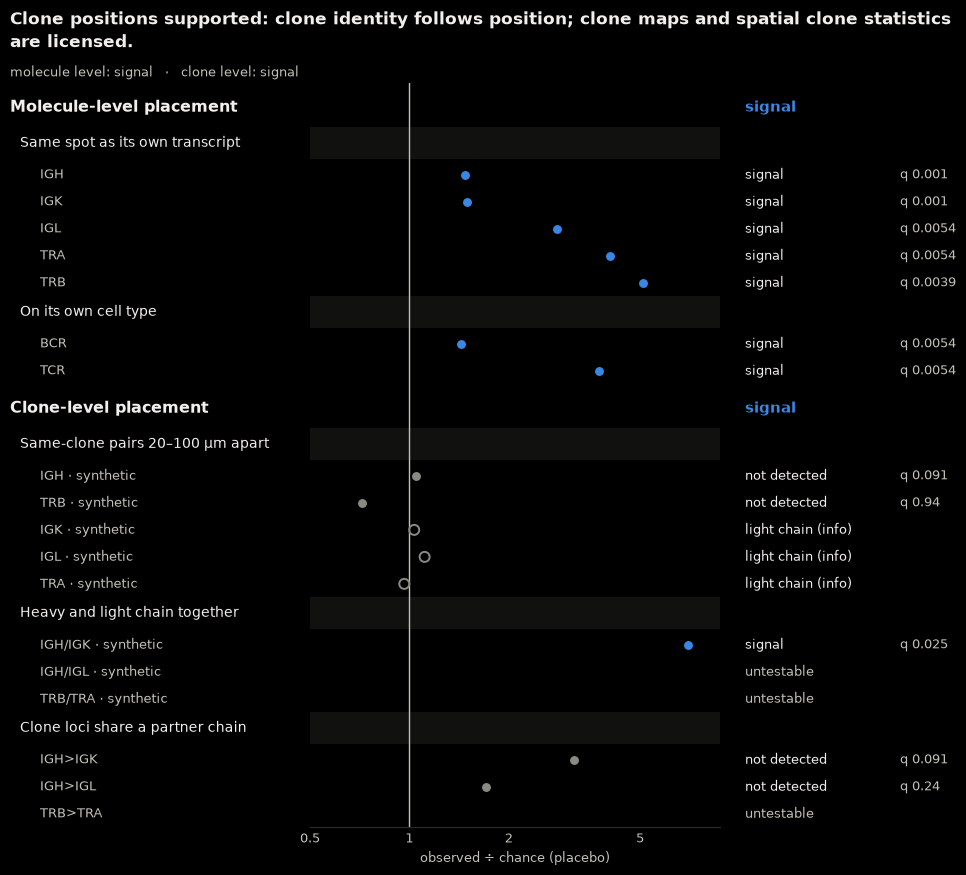

In [8]:
fig = report.plot()
plt.show()

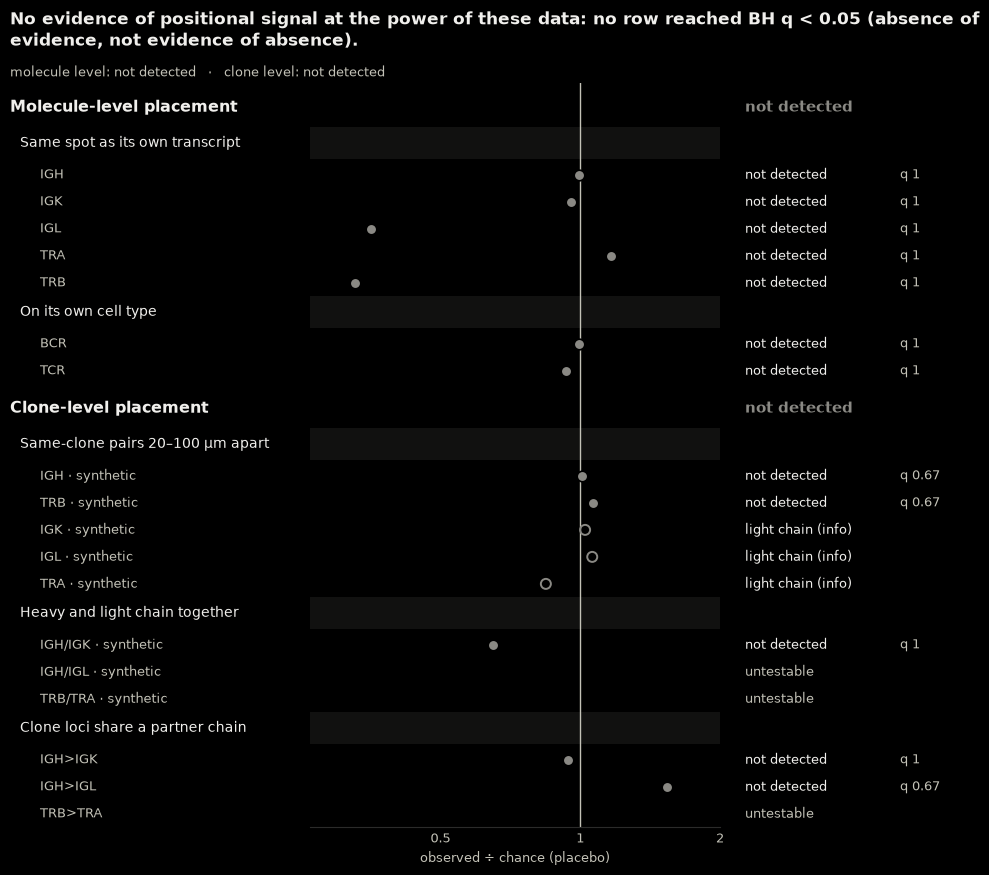

In [9]:
fig = report_broken.plot()
plt.show()

## Methods text and the underlying results

`report.methods()` writes a methods paragraph with the parameters and references, and `report.to_markdown(path)` the
whole report. Every underlying result object is kept in `report.results`, so any row can be inspected in full; steps
that could not run are listed with the reason in `report.results["skipped"]`.

In [10]:
print(report.methods())

Location trust was assessed with spaclone 1.0.0 on 7,954 receptor records (7,738 after filtering: valid IMGT junction, productive). Molecule-level placement (is a molecule on its own transcript / cell type?) and clone-level placement (does clone identity follow position?) were judged separately. Molecule-level concordance with the GEX library was tested on spots carrying a single clone of the chain, against a per-spot chance model from the local transcript composition, and the located fraction was bounded with a Rogan-Gladen-type estimator (Rogan & Gladen 1978). The share of records on their own cell type was compared with random placement of whole spots on typed units of the same library, drawn with probability proportional to captured cDNA, after barcode sinks were removed (Gel et al. 2016). Cell types were taken from gex.obs['cell_type'] (cell_type_key='auto': gex.obs['cell_type'] exists); own cell types: BCR B, GC B, plasma (own_types='auto'); TCR T (own_types='auto'). Same-clone c

In [11]:
print(sorted(report.results))
report.results["colocalisation"].table[["locus", "design", "band", "n_units", "statistic", "null_mean", "ratio", "p_value"]]

['barcode_sinks', 'colocalisation', 'colocalisation_light', 'own_type_share_BCR', 'own_type_share_TCR', 'pairing_BCR', 'pairing_TCR', 'read_floor_IGH_IGK', 'read_floor_IGH_IGL', 'read_floor_TRB_TRA', 'same_spot', 'skipped']


,locus,design,band,n_units,statistic,null_mean,ratio,p_value
0,IGH,stratified,0-20,2184,0.002655,0.002853,0.930669,0.656716
1,IGH,stratified,20-100,2184,0.140597,0.134481,1.045476,0.054726
2,IGH,whole_sample,0-20,2184,0.002655,0.002890,0.918523,0.711443
3,IGH,whole_sample,20-100,2184,0.140597,0.137222,1.024593,0.223881
4,TRB,stratified,0-20,258,0.000000,0.002573,0.000000,1.000000
5,TRB,stratified,20-100,258,0.110390,0.153205,0.720534,0.935323
6,TRB,whole_sample,0-20,258,0.000000,0.002869,0.000000,1.000000
7,TRB,whole_sample,20-100,258,0.110390,0.152320,0.724723,0.925373


The QC table and the filtering report from the first two steps are kept too:

In [12]:
report.filtering

,step,rule,applied,failing,removed,spots_removed,clones_removed,records,spots,clones
0,0,input,True,0,0,0,0,7954,5468,1245
1,1,"valid junction (C...W/F, 20 aa, >= 5 aa)",True,216,216,108,20,7738,5360,1225
2,2,productive,True,216,0,0,0,7738,5360,1225


## What to do next

* `02_is_my_data_spatial`: the same call on real public data (AIR-SPACE lymph node and Stereo-XCR-seq lung cancer),
  and why published quality metrics pass even when positions are random.
* `03_bcr_class_switching_and_mutation`: isotypes, class-switch maps, somatic mutation and lineage trees in tissue.
* `04_transcriptome_and_repertoire`: the GEX workflow (regions, pseudobulk DE) and spatial repertoire statistics.
* `05_custom_placebo`: test your own statistic against random placement.
* `06_hotspots_and_lineages`: the flagship workflow on a mouse spleen, from two files to class-switch and mutation
  hotspots, lineage trees on the tissue, sciCSR transitions and Threadfin clone states.

In [13]:
print(f"notebook run time: {time.time() - t_start:.0f} s")

notebook run time: 12 s
